In [1]:
import sys
sys.path.append("..")

import numpy as np
import tensorflow as tf

from functions import BunDLeNet, BunDLeTrainer
from data_reader import DataReader
from processed_data_storage import ProcessedDataStroage
from preprocess import Preprocessor

# "Trainingsepoche" = ein Durchlauf durch alle Trainingsfenster.
# Nicht verwechseln mit den EEG-Epochen (Zeitabschnitte um ein Bild herum).
number_of_training_epochs = 20
subjects_range = range(1, 3)

data_reader = DataReader()
processed_data_storage = ProcessedDataStroage()

for sub in subjects_range:
    subject = sub + 100
    subject = str(subject)
    raw, channels, events = data_reader.read_data(
        subject=str(subject),
    )

    preprocessor = Preprocessor(raw)
    del raw

    preprocessor.run_pipeline(use_filter=True, use_ica=False, use_autoreject=False)

    epochs_train, epochs_test = preprocessor.split_train_test()

    X_train, X_test = preprocessor.scale(epochs_train.get_data(), epochs_test.get_data())

    labels_train, _ = preprocessor.create_labels_for_epochs(epochs_train)    # Form (1638, 120)
    labels_test, _ = preprocessor.create_labels_for_epochs(epochs_test)      # Form (410, 120)

    processed_data_storage.save_subject(subject, {"X_train": X_train, "X_test": X_test, "labels_train": labels_train, "labels_test": labels_test})

I0000 00:00:1794768277.579759   55059 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794768277.618814   55059 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794768278.533924   55059 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


None
Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download
Lese BrainVision-Aufnahme ein: /home/bened/bachelor-thesis/data/raw/ds005363-download/sub-101/ses-01/eeg/sub-101_ses-01_task-objrecog_eeg.vhdr
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 3301 samples (3.301 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.019

In [ ]:
X_train = []
X_test = []
labels_train = []
labels_test = []

for sub in subjects_range:
    subject = sub + 100
    values = processed_data_storage.load_subject(subject)
    X_train.append(values[0])
    X_test.append(values[1])
    labels_train.append(values[2])
    labels_test.append(values[3])

X_train = np.concatenate(X_train, axis=0)
X_test = np.concatenate(X_test, axis=0)
labels_train = np.concatenate(labels_train, axis=0)
labels_test = np.concatenate(labels_test, axis=0)

number_of_epochs, number_of_channels, number_of_time_points = X_train.shape
print(f"X_train shape: {X_train.shape}")
print(f"Number of epochs: {number_of_epochs}")
print(f"Number of channels: {number_of_channels}")

# Alle Fensterpaare der Trainingsdaten (darauf wird trainiert)
epoch_numbers, start_time_points = preprocessor.list_all_window_pairs(
    number_of_epochs, number_of_time_points, preprocessor.WINDOW_LENGTH
)

# Alle Fensterpaare der Testdaten (werden nur ausgewertet, nie trainiert)
number_of_test_epochs = X_test.shape[0]
number_of_test_time_points = X_test.shape[2]
test_epoch_numbers, test_start_time_points = preprocessor.list_all_window_pairs(
    number_of_test_epochs, number_of_test_time_points, preprocessor.WINDOW_LENGTH
)

# Feste Zufallsauswahl an Trainingsfenstern, genauso viele wie Testfenster.
# Auf dieser Auswahl messen wir nach jeder Trainingsepoche Loss und Genauigkeit
# auf genau dieselbe Art wie auf den Testdaten.
random_generator = np.random.default_rng(11)
train_subset_indices = random_generator.choice(
    len(epoch_numbers), size=len(test_epoch_numbers), replace=False
)
train_subset_epoch_numbers = epoch_numbers[train_subset_indices]
train_subset_start_time_points = start_time_points[train_subset_indices]

print(f"Trainingsfenster: {len(epoch_numbers)}, davon ausgewertet: {len(train_subset_epoch_numbers)}")
print(f"Testfenster: {len(test_epoch_numbers)}")

# Zufallswert (reines Raten) als Vergleichslinie.
# Das Ziel eines Fensterpaares ist das Label am Index start + WINDOW_LENGTH,
# also frühestens am Index WINDOW_LENGTH. Davor liegende Labels kommen als Ziel nie vor.
target_labels_that_can_occur = labels_train[:, preprocessor.WINDOW_LENGTH:]
target_categories = np.unique(target_labels_that_can_occur)
number_of_target_categories = len(target_categories)
chance_loss = np.log(number_of_target_categories)
chance_accuracy = 1 / number_of_target_categories
print(f"Kategorien, die als Ziel vorkommen: {target_categories}")
print(f"Raten ergibt Loss ln({number_of_target_categories}) = {chance_loss:.3f} und Genauigkeit {chance_accuracy:.2f}")

X_train shape: (3276, 64, 120)
Number of epochs: 3276
Number of channels: 64
Trainingsfenster: 343980, davon ausgewertet: 86100
Testfenster: 86100
[0. 0. 0. ... 0. 0. 0.]
Kategorien, die als Ziel vorkommen: [0. 1. 2. 3. 4.]
Raten ergibt Loss ln(5) = 1.609 und Genauigkeit 0.20


In [3]:
behaviour_loss_function = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)


def evaluate_windows(model, eeg_data, labels, epoch_numbers, start_time_points):
    """Berechnet Behavior-Loss und Genauigkeit auf den gegebenen Fensterpaaren.

    Das Modell wird dabei nicht verändert (kein Training).
    """
    sum_of_losses = 0.0
    number_of_correct_predictions = 0
    number_of_windows = len(epoch_numbers)

    for batch_start in range(0, number_of_windows, preprocessor.BATCH_SIZE):
        batch_end = batch_start + preprocessor.BATCH_SIZE

        window_pairs, target_labels = preprocessor.build_training_batch(
            eeg_data,
            labels,
            epoch_numbers[batch_start:batch_end],
            start_time_points[batch_start:batch_end],
            preprocessor.WINDOW_LENGTH,
        )
        target_labels = target_labels.astype(np.int64)

        # training=False schaltet die GaussianNoise-Schicht aus
        _, _, predicted_scores = model(
            tf.convert_to_tensor(window_pairs, dtype=tf.float32), training=False
        )

        # Der Loss ist ein Mittelwert über den Batch. Der letzte Batch ist kleiner,
        # deshalb gewichten wir mit der Batchgröße und teilen am Ende durch alle Fenster.
        batch_loss = float(behaviour_loss_function(target_labels, predicted_scores))
        number_of_windows_in_batch = len(target_labels)
        sum_of_losses = sum_of_losses + batch_loss * number_of_windows_in_batch

        # Vorhergesagte Kategorie = Ausgang mit dem höchsten Wert
        predicted_categories = np.argmax(predicted_scores.numpy(), axis=1)
        for window_number in range(number_of_windows_in_batch):
            if predicted_categories[window_number] == target_labels[window_number]:
                number_of_correct_predictions = number_of_correct_predictions + 1

    mean_loss = sum_of_losses / number_of_windows
    accuracy = number_of_correct_predictions / number_of_windows
    return mean_loss, accuracy

In [4]:
# Modell hier neu anlegen: Wenn man nur diese Zelle erneut ausführt,
# startet das Training von vorne statt mit dem alten Modell weiterzumachen.
model = BunDLeNet(3)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
trainer = BunDLeTrainer(model, optimizer)

all_losses = []           # pro Batch: [Markov, Behavior, Total]
history_per_epoch = []    # pro Trainingsepoche: [Train-Loss, Train-Genauigkeit, Test-Loss, Test-Genauigkeit]

for training_epoch in range(number_of_training_epochs):
    shuffled_order = random_generator.permutation(len(epoch_numbers))
    for batch_start in range(0, len(shuffled_order), preprocessor.BATCH_SIZE):
        selected_pairs = shuffled_order[batch_start : batch_start + preprocessor.BATCH_SIZE]

        window_pairs, target_labels = preprocessor.build_training_batch(
            X_train,
            labels_train,
            epoch_numbers[selected_pairs],
            start_time_points[selected_pairs],
            preprocessor.WINDOW_LENGTH,
        )

        markov_loss, behaviour_loss, total_loss = trainer.train_step(
            tf.convert_to_tensor(window_pairs, dtype=tf.float32),
            tf.convert_to_tensor(target_labels, dtype=tf.int64),
            gamma=preprocessor.GAMMA,
        )
        all_losses.append([float(markov_loss), float(behaviour_loss), float(total_loss)])

    # Nach jeder Trainingsepoche: Training und Test auf dieselbe Art auswerten
    train_loss, train_accuracy = evaluate_windows(
        model, X_train, labels_train, train_subset_epoch_numbers, train_subset_start_time_points
    )
    test_loss, test_accuracy = evaluate_windows(
        model, X_test, labels_test, test_epoch_numbers, test_start_time_points
    )
    history_per_epoch.append([train_loss, train_accuracy, test_loss, test_accuracy])

    print(
        f"Trainingsepoche {training_epoch + 1}/{number_of_training_epochs}: "
        f"Loss Training {train_loss:.3f} / Test {test_loss:.3f}, "
        f"Genauigkeit Training {train_accuracy:.3f} / Test {test_accuracy:.3f}"
    )

W0000 00:00:1794768307.978519   55059 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1794768307.980839   55059 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794768308.093405   55059 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:03:00.0, compute capability: 12.0a


Trainingsepoche 1/20: Loss Training 1.474 / Test 1.477, Genauigkeit Training 0.255 / Test 0.250
Trainingsepoche 2/20: Loss Training 1.426 / Test 1.432, Genauigkeit Training 0.272 / Test 0.246
Trainingsepoche 3/20: Loss Training 1.383 / Test 1.392, Genauigkeit Training 0.304 / Test 0.268
Trainingsepoche 4/20: Loss Training 1.369 / Test 1.380, Genauigkeit Training 0.310 / Test 0.280
Trainingsepoche 5/20: Loss Training 1.360 / Test 1.372, Genauigkeit Training 0.315 / Test 0.279
Trainingsepoche 6/20: Loss Training 1.352 / Test 1.368, Genauigkeit Training 0.323 / Test 0.296
Trainingsepoche 7/20: Loss Training 1.342 / Test 1.362, Genauigkeit Training 0.330 / Test 0.303
Trainingsepoche 8/20: Loss Training 1.327 / Test 1.357, Genauigkeit Training 0.343 / Test 0.315
Trainingsepoche 9/20: Loss Training 1.315 / Test 1.356, Genauigkeit Training 0.352 / Test 0.316
Trainingsepoche 10/20: Loss Training 1.305 / Test 1.355, Genauigkeit Training 0.359 / Test 0.319
Trainingsepoche 11/20: Loss Training 1.

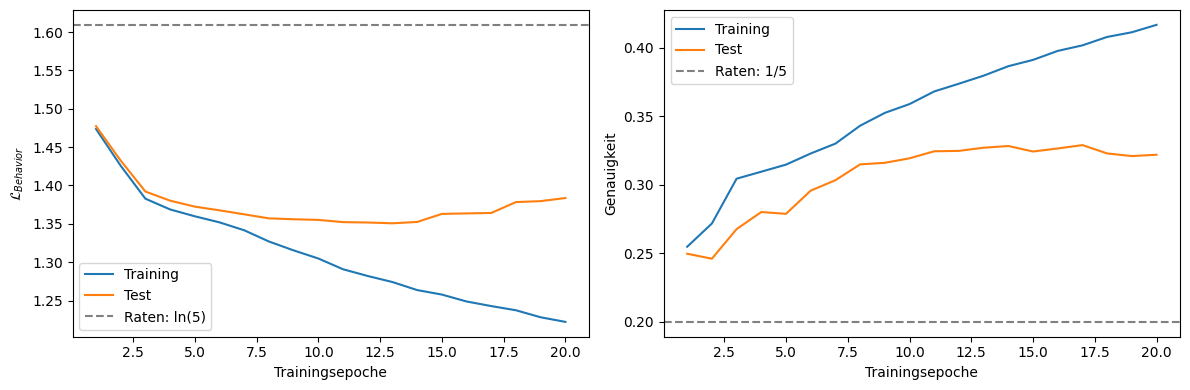

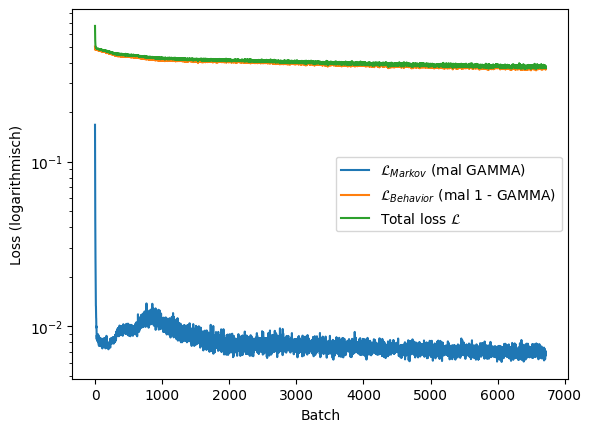

In [5]:
import matplotlib.pyplot as plt

# 1) Training und Test pro Trainingsepoche
history = np.array(history_per_epoch)    # Form (Anzahl Trainingsepochen, 4)
epoch_axis = np.arange(1, len(history) + 1)

figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(12, 4))

loss_axis.plot(epoch_axis, history[:, 0], label="Training")
loss_axis.plot(epoch_axis, history[:, 2], label="Test")
loss_axis.axhline(chance_loss, color="gray", linestyle="--", label=f"Raten: ln({number_of_target_categories})")
loss_axis.set_xlabel("Trainingsepoche")
loss_axis.set_ylabel(r"$\mathcal{L}_{Behavior}$")
loss_axis.legend()

accuracy_axis.plot(epoch_axis, history[:, 1], label="Training")
accuracy_axis.plot(epoch_axis, history[:, 3], label="Test")
accuracy_axis.axhline(chance_accuracy, color="gray", linestyle="--", label=f"Raten: 1/{number_of_target_categories}")
accuracy_axis.set_xlabel("Trainingsepoche")
accuracy_axis.set_ylabel("Genauigkeit")
accuracy_axis.legend()

plt.tight_layout()
plt.show()

# 2) Verlauf pro Batch (mit Rauschen der GaussianNoise-Schicht)
# total = GAMMA * Markov + (1 - GAMMA) * Behavior. Bei GAMMA = 0 ist der Markov-Anteil
# immer 0 (auf einer log-Achse nicht darstellbar) und Total ist gleich Behavior.
# Deshalb zeichnen wir nur die Kurven, die etwas Eigenes zeigen.
loss_history = np.array(all_losses)      # Form (Anzahl Batches, 3)

plt.figure()
if preprocessor.GAMMA > 0:
    plt.semilogy(loss_history[:, 0], label=r"$\mathcal{L}_{Markov}$ (mal GAMMA)")
if preprocessor.GAMMA < 1:
    plt.semilogy(loss_history[:, 1], label=r"$\mathcal{L}_{Behavior}$ (mal 1 - GAMMA)")
if 0 < preprocessor.GAMMA < 1:
    plt.semilogy(loss_history[:, 2], label=r"Total loss $\mathcal{L}$")
plt.xlabel("Batch")
plt.ylabel("Loss (logarithmisch)")
plt.legend()
plt.show()